# 05 · How the models behave: amount of data and model complexity

Two experiments, for task (a) (conference ranking) and task (c) (penalty minutes):

1. **Learning curve (how much data is needed).** For every test season, the model learns from only the last 1, 3, 5, 10 or 20 seasons before it, or from all of them (from 1979). We start very small and grow, and watch the test error. This shows whether more data still helps, and whether starting in 1979 is enough.
2. **Complexity curve (overfitting).** A decision tree with more and more questions in a row (depth). We measure the error on the seasons it learned from (the last 3 training seasons) and on new seasons. When the training error keeps falling but the test error rises, the tree is memorising: overfitting.

Same test as everywhere else: `evaluate_by_season`, 9 test seasons 2000–2009, never learning from the season being predicted. Figures are saved in `figures/`.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from src.evaluation import (test_seasons, evaluate_by_season, conference_rank, true_strength,
                            mean_conference_rank_error, pim_mae)

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
team_table = pd.read_csv("../data/team_table.csv")
player_table = pd.read_csv("../data/player_table.csv")
seasons = test_seasons(team_table)

# Conference table for (a): same construction as in notebook 03
teams_raw = pd.read_csv("../hockey_development_data/Teams.csv")
t = teams_raw[teams_raw["lgID"] == "NHL"].copy()
t["pts_vs_avg"] = (t["Pts"] / t["G"]) / t.groupby("year")["Pts"].transform("sum").div(t.groupby("year")["G"].transform("sum"))
t["gd_per_game"] = (t["GF"] - t["GA"]) / t["G"]
t = t.sort_values(["franchID", "year"])
t["last_gd_per_game"] = t.groupby("franchID")["gd_per_game"].shift(1)
t["conf_rank"] = conference_rank(t, true_strength(t))
conf_table = team_table.merge(t[["year", "franchID", "confID", "pts_vs_avg", "last_gd_per_game", "conf_rank"]],
                              on=["year", "franchID"], how="left")
before_tests = conf_table["year"] < seasons[0]   # fill new teams only from seasons before the first test season (no future data)
conf_table["last_gd_per_game"] = conf_table["last_gd_per_game"].fillna(conf_table.loc[before_tests, "last_gd_per_game"].quantile(0.15))

F_A = ["last_pts_vs_avg", "avg3_pts_vs_avg", "last_gd_per_game"]                       # best linear model for (a)
F_A_TREE = F_A + ["roster_pts_vs_avg", "roster_goalie_ga_vs_avg"]
F_C = ["PIM_1", "PIM_2", "PIM_3", "GP_1", "GP_2", "GP_3", "rate_1", "career_rate", "marcel_rate_vs_league",
       "games_guess", "pts_rate_1", "seasons_before", "first_season", "pos_C", "pos_D", "pos_L", "pos_R", "pos_G",
       "team_style_last", "league_rate_last"]                                            # same inputs as notebook 04

def last_n_seasons(train, n):
    keep = sorted(train["year"].unique())[-n:]
    return train[train["year"].isin(keep)]
print(conf_table.shape, player_table.shape)

(753, 23) (24712, 34)


## 1. Learning curves

- (a): the linear model with goal difference (the best one in notebook 03).
- (c): gradient boosting with absolute error (the best one in notebook 04), with its most chosen setting.

Dashed line: the simple guess, which needs no training.

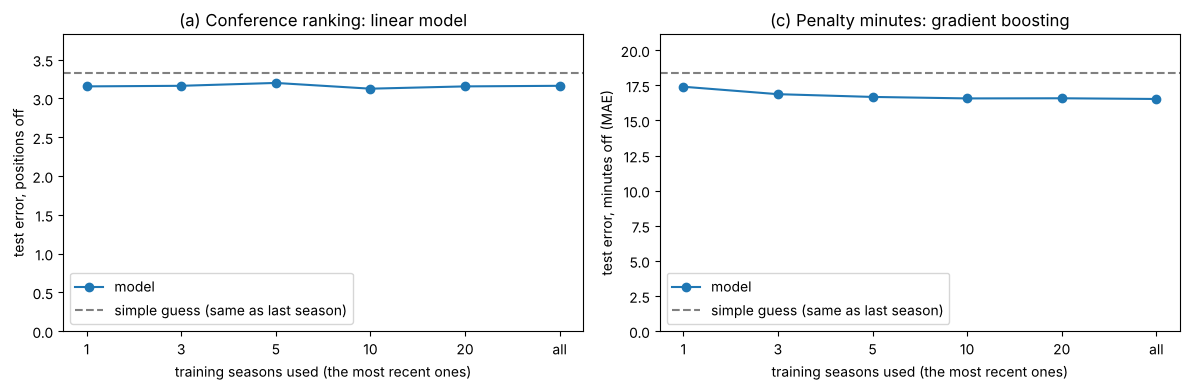

,(a) positions off,(c) minutes off
1,3.16,17.40
3,3.16,16.87
5,3.20,16.68
10,3.13,16.57
20,3.16,16.58
all,3.16,16.53


In [2]:
WINDOWS = [1, 3, 5, 10, 20, 99]   # 99 = all seasons since 1979
LABELS = ["1", "3", "5", "10", "20", "all"]

def a_model(n):
    def predict(train, test):
        train = last_n_seasons(train, n)
        model = LinearRegression().fit(train[F_A], train["pts_vs_avg"])
        return conference_rank(test, model.predict(test[F_A]))
    return predict

def c_model(n):
    def predict(train, test):
        train = last_n_seasons(train, n)
        model = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_leaf_nodes=7, max_iter=300,
                                              min_samples_leaf=40, random_state=0).fit(train[F_C], train["PIM"])
        return np.clip(model.predict(test[F_C]), 0, None)
    return predict

curve_a = [evaluate_by_season(conf_table, a_model(n), mean_conference_rank_error, seasons)["score"].mean() for n in WINDOWS]
curve_c = [evaluate_by_season(player_table, c_model(n), pim_mae, seasons)["score"].mean() for n in WINDOWS]
simple_a = evaluate_by_season(conf_table, lambda tr, te: conference_rank(te, te["last_pts_vs_avg"]), mean_conference_rank_error, seasons)["score"].mean()
def same_as_last_c(train, test):   # same rule as notebook 04: first-season players get the median of first-season players of their position
    firsts = train[train["first_season"] == 1]
    fill = test["pos"].map(firsts.groupby("pos")["PIM"].median()).fillna(firsts["PIM"].median())
    return test["PIM_1"].fillna(fill).values
simple_c = evaluate_by_season(player_table, same_as_last_c, pim_mae, seasons)["score"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, curve, simple, title, unit in [(axes[0], curve_a, simple_a, "(a) Conference ranking: linear model", "positions off"),
                                       (axes[1], curve_c, simple_c, "(c) Penalty minutes: gradient boosting", "minutes off (MAE)")]:
    ax.plot(LABELS, curve, marker="o", label="model")
    ax.axhline(simple, ls="--", color="grey", label="simple guess (same as last season)")
    ax.set(xlabel="training seasons used (the most recent ones)", ylabel=f"test error, {unit}", title=title)
    ax.set_ylim(0, max(max(curve), simple) * 1.15)   # axis from 0, so small differences are not exaggerated
    ax.legend()
plt.tight_layout(); plt.savefig(FIG / "learning_curves.png", dpi=150); plt.show()
pd.DataFrame({"(a) positions off": np.round(curve_a, 2), "(c) minutes off": np.round(curve_c, 2)}, index=LABELS)

### What the learning curves show

- **(a) is flat:** the linear model is about as good with 1 season of data as with all of them (3.13–3.20 positions off). It has only 3 inputs, so 1 season (about 30 teams) is enough to learn 3 weights. More data cannot help it; only new information could.
- **(c) keeps improving until about 10 seasons** (17.4 minutes off with 1 season, 16.6 with 10), then stays flat. Gradient boosting has many more decisions to learn, so it needs more examples (one season is about 900 players).
- **Starting in 1979 is enough:** every test season has at least 21 training seasons, more than either model needs. Using even older seasons would add eras with different rules (the WHA years, other playoff formats) without lowering the error.

## 2. Complexity curves: decision tree depth

A decision tree with depth 1 (one question) up to depth 12–16 (many questions in a row), no other limit, so it can memorise freely.
- (a): the tree predicts points from the 5 inputs; error = positions off in the conference.
- (c): the tree predicts PIM from the 20 inputs; error = minutes off.

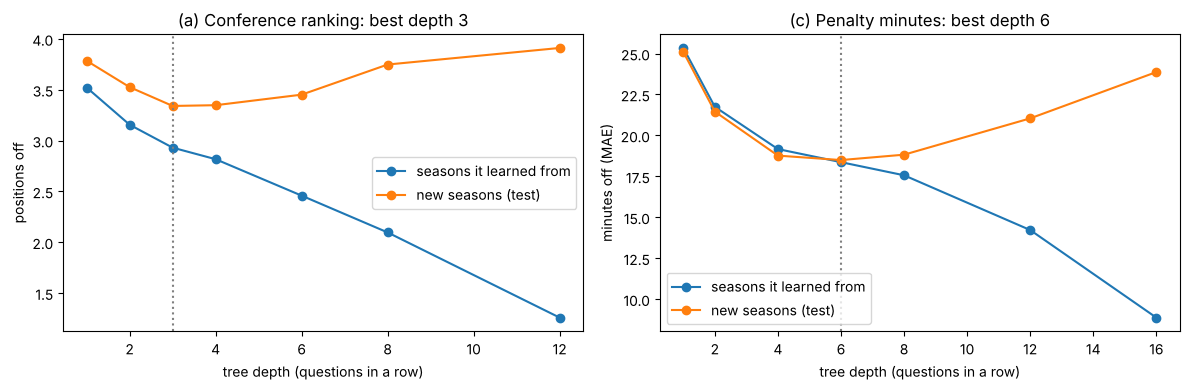

(a)                       (c)           
      training error test error training error test error
depth                                                    
1               3.52       3.79          25.34      25.10
2               3.16       3.53          21.75      21.45
3               2.93       3.34            NaN        NaN
4               2.82       3.35          19.17      18.77
6               2.46       3.45          18.37      18.50
8               2.10       3.75          17.57      18.82
12              1.26       3.91          14.22      21.04
16               NaN        NaN           8.87      23.87

In [3]:
def depth_curve(table, features, target, depths, error_of):
    rows = []
    for d in depths:
        train_err, test_err = [], []
        for s in seasons:
            train, test = table[table["year"] < s], table[table["year"] == s]
            tree = DecisionTreeRegressor(max_depth=d, random_state=0).fit(train[features].fillna(-1), train[target])
            test_err.append(error_of(test, tree.predict(test[features].fillna(-1))))
            recent = [y for y in sorted(train["year"].unique())[-3:]]
            train_err.append(np.mean([error_of(train[train["year"] == y], tree.predict(train[train["year"] == y][features].fillna(-1)))
                                      for y in recent]))
        rows.append({"depth": d, "training error": np.mean(train_err), "test error": np.mean(test_err)})
    return pd.DataFrame(rows).set_index("depth")

err_a = lambda test, pred: mean_conference_rank_error(test, conference_rank(test, pred))
depth_a = depth_curve(conf_table, F_A_TREE, "pts_vs_avg", [1, 2, 3, 4, 6, 8, 12], err_a)
depth_c = depth_curve(player_table, F_C, "PIM", [1, 2, 4, 6, 8, 12, 16], pim_mae)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, curve, title, unit in [(axes[0], depth_a, "(a) Conference ranking", "positions off"),
                               (axes[1], depth_c, "(c) Penalty minutes", "minutes off (MAE)")]:
    ax.plot(curve.index, curve["training error"], marker="o", label="seasons it learned from")
    ax.plot(curve.index, curve["test error"], marker="o", label="new seasons (test)")
    best = curve["test error"].idxmin()
    ax.axvline(best, ls=":", color="grey")
    ax.set(xlabel="tree depth (questions in a row)", ylabel=unit, title=f"{title}: best depth {best}")
    ax.legend()
plt.tight_layout(); plt.savefig(FIG / "tree_depth_curves.png", dpi=150); plt.show()
pd.concat({"(a)": depth_a.round(2), "(c)": depth_c.round(2)}, axis=1)

### What the complexity curves show

- **Both show overfitting clearly.** As the tree gets deeper, the error on the seasons it learned from keeps falling, but on new seasons it first falls and then rises again.
- **(a): the best depth is 3.** From depth 4 on, the training error keeps dropping (down to about 1.3 positions at depth 12) while the test error climbs back to about 3.9, worse than the simple guess (3.33). With about 30 teams per season, a deep tree soon has one final box per few teams: it memorises them, including their luck.
- **(c): the best depth is about 6.** There are far more players, so the tree can ask more questions before memorising. At depth 16 the training error is 8.9 minutes but the test error is 23.9: pure memorising.
- **This is why the practice test limits depth and leaf size,** and why the final models are simple (linear for (a)) or built from many small trees that each ask few questions (gradient boosting for (c)).